## $\delta=6$, $\alpha=0.1$

Paper figures 9. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS:
    from WERM.signal_priors import SparseGaussianSignal
    import WERM.model
    import WERM.performance_measures
    import importlib
    import WERM.comparison
    importlib.reload(WERM.comparison)
    import WERM.estimators
    from WERM.config import η_to_ψ
    import numpy as np
    import jax.numpy as jnp
    import jax
    jax.config.update('jax_enable_x64', True)
    import numpy.random as nprandom
    import matplotlib.pyplot as plt
    plt.switch_backend('module://matplotlib_inline.backend_inline')
    from functools import partial
    from tqdm.auto import tqdm
    import time
    from joblib import Parallel, delayed
    from joblib.externals.loky.process_executor import TerminatedWorkerError
    from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv, glm_bsa3_cv as _glm_bsa3_cv
    import logging
    from datetime import datetime, timedelta
    import sys
    import pickle
    import os
    os.environ['JAX_ENABLE_X64'] = 'True'
    random_seed = 42

    def _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx):
        return os.path.join(checkpoint_dir, f'setting_{int(setting_idx):02d}_trial_{int(trial_idx):03d}.pkl')

    def _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result):
        """Atomically persist one deterministic trial before returning it to joblib."""
        (setting_idx, trial_idx, trial_result) = result
        os.makedirs(checkpoint_dir, exist_ok=True)
        path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
        tmp_path = f'{path}.tmp-{os.getpid()}'
        payload = {'signature': checkpoint_signature, 'setting_idx': int(setting_idx), 'trial_idx': int(trial_idx), 'result': result}
        with open(tmp_path, 'wb') as checkpoint_file:
            pickle.dump(payload, checkpoint_file, protocol=pickle.HIGHEST_PROTOCOL)
            checkpoint_file.flush()
            os.fsync(checkpoint_file.fileno())
        os.replace(tmp_path, path)

    def _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx):
        """Return a validated checkpoint, or None when absent/corrupt/incompatible."""
        path = _trial_checkpoint_path(checkpoint_dir, setting_idx, trial_idx)
        if not os.path.exists(path):
            return None
        try:
            with open(path, 'rb') as checkpoint_file:
                payload = pickle.load(checkpoint_file)
            if payload.get('signature') != checkpoint_signature:
                return None
            result = payload['result']
            if (int(result[0]), int(result[1])) != (int(setting_idx), int(trial_idx)):
                return None
            data_hash = result[2].get('data_hash')
            if not isinstance(data_hash, str) or len(data_hash) != 32:
                return None
            return result
        except Exception as checkpoint_error:
            return None

    def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates, method_configs, checkpoint_dir=None, checkpoint_signature=None, existing_trial_result=None):
        """
        Executes a single simulation trial for a given delta, running multiple methods.
        This function is designed to be called in parallel by joblib.
        """
        (i, κ, j) = params
        trial_start_time = time.time()
        rng = _trial_rng('M3d-redo-successive-halving', i, j)
        δ = fixed_delta
        n = int(δ * p)
        true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        α = signal_alpha
        σ_l_arr = κ * np.sqrt(δ) * np.ones(L)
        signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)
        data_gen_start = time.time()
        B̃ = signal_prior.sample(p, rng=rng)
        X = rng.normal(0, np.sqrt(1 / n), (n, p))
        ε = rng.uniform(0, 1, size=(n,))
        X = X @ np.linalg.cholesky(Sigma).T
        true_chgpts = true_chgpt_locations_fn(n)
        C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)
        X_scaled = X * np.sqrt(n)
        B̃_scaled = B̃ / np.sqrt(n)
        Θ = X_scaled @ B̃_scaled
        y = np.array(jax.vmap(WERM.model.q_logistic_model, in_axes=(0, 0, 0))(Θ, C_true, ε))
        data_gen_time = time.time() - data_gen_start
        current_data_hash = _data_hash(X, y)
        if existing_trial_result is not None:
            if existing_trial_result.get('data_hash') != current_data_hash:
                raise RuntimeError(f'legacy checkpoint data hash mismatch at setting={i}, trial={j}')
            trial_results = dict(existing_trial_result)
            methods_status = {method_name: False for method_name in method_configs.keys()}
            methods_status.update(existing_trial_result.get('methods_status', {}))
        else:
            trial_results = {'data_hash': current_data_hash}
            methods_status = {method_name: False for method_name in method_configs.keys()}
        reused_methods = []
        for (method_name, method_func_info) in method_configs.items():
            try:
                if f'status_{method_name}' in trial_results:
                    reused_methods.append(method_name)
                    continue
                method_start = time.time()
                cp = np.array([])
                if method_name in glmbsa_cv_folds:
                    delta_fraction = 1 / 10
                    (selected_c1, cp, glmbsa_cv_scores) = _glm_bsa3_cv(X_scaled, y, kmax=glmbsa_kmax, delta=delta_fraction, c1_candidates=glmbsa_c1_candidates, num_folds=glmbsa_cv_folds[method_name])
                    trial_results[f'selected_c1_{method_name}'] = float(selected_c1)
                    trial_results[f'cv_scores_{method_name}'] = np.asarray(glmbsa_cv_scores).copy()
                elif method_name == 'WERM-L1-fullCV-2fold':
                    cv_folds = 2
                    l1_constants = joint_l1_constants
                    ((best_segments, best_C), cp, variant_cv_diagnostics) = _weighted_erm_joint_cv(X=X_scaled, y=y, M=M, M_scorer=M, Lmax=L, delta_fraction=1 / 10, l1_constants=l1_constants, num_folds=cv_folds, n_jobs=1, selection_strategy='exhaustive', return_diagnostics=True, coefficient_loss='logistic', coefficient_solver_options={'tol': 1e-06, 'max_iter': 20000})
                    trial_results[f'full_cv_{method_name}'] = variant_cv_diagnostics
                    trial_results[f'selected_segments_{method_name}'] = int(best_segments)
                    trial_results[f'selected_num_chgpts_{method_name}'] = int(best_segments - 1)
                    trial_results[f'selected_l1_constant_{method_name}'] = float(best_C)
                    trial_results[f'selected_l1_lambda_{method_name}'] = float(best_C * np.sqrt(2 * np.log(p) / n))
                else:
                    continue
                method_time = time.time() - method_start
                evaluation = _evaluate_changepoints(cp, true_chgpts, n)
                raw_cp = evaluation['raw_cp']
                trial_results[f'runtime_{method_name}'] = method_time
                trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
                trial_results[f'status_{method_name}'] = evaluation['status']
                trial_results[f'haus_{method_name}'] = evaluation['haus']
                trial_results[f'size_{method_name}'] = evaluation['size']
                trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
                methods_status[method_name] = evaluation['status'] != 'not_applicable'
            except Exception as e:
                raise
        trial_results['n'] = n
        trial_results['true_chgpts'] = true_chgpts.copy()
        trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
        trial_results['methods_status'] = methods_status
        trial_results['reused_methods'] = tuple(reused_methods)
        trial_total_time = time.time() - trial_start_time
        log_message_parts = [f'Completed trial {j + 1} for κ={κ:.2f}: ', f'Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)']
        for method_name in method_configs.keys():
            status_str = trial_results[f'status_{method_name}']
            runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and (not np.isnan(trial_results[f'runtime_{method_name}'])) else 'N/A'
            log_message_parts.append(f'{method_name}={status_str} ({runtime_str})')
        result = (i, j, trial_results)
        if checkpoint_dir is not None:
            _write_trial_checkpoint(checkpoint_dir, checkpoint_signature, result)
        return result
    p = 200
    L = 4
    noise_std = np.sqrt(0.6)
    fixed_delta = 6.0
    signal_alpha = 0.1
    kappa_list = np.sqrt([1.0, 10.0, 25.0, 50.0, 100.0, 500.0, 1000.0, 2000.0])
    num_trials = 100
    fractional_chgpt_locations = np.array([1 / 3, 8 / 15])
    glmbsa_c1_candidates = (0.018, 0.18, 1.8)
    joint_l1_constants = (0.03, 0.3, 3.0)
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36))

    def sample_corr(p, df=10, seed=None):
        """Sample a random correlation matrix using the Haar measure."""
        rng = np.random.default_rng(seed)
        (Q, _) = np.linalg.qr(rng.standard_normal((p, p)))
        λ = rng.chisquare(df, size=p)
        B = Q.T @ np.diag(λ) @ Q
        D = np.sqrt(np.diag(B))
        return B / np.outer(D, D)
    Sigma = sample_corr(p, df=10, seed=random_seed)
    glmbsa_kmax = L - 2
    glmbsa_cv_folds = {'GLMBSA-CV': 2}
    methods_to_evaluate = [{'name': 'GLMBSA-CV', 'label': 'GLMBSA', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'}, {'name': 'WERM-L1-fullCV-2fold', 'label': '\\textbf{WERM+L1}', 'color': 'black', 'marker': 'D', 'linestyle': '-'}]
    method_configs = {method['name']: method for method in methods_to_evaluate}
    method_names_list = [m['name'] for m in methods_to_evaluate]
    results = {'successful_trials': {method['name']: np.zeros(len(kappa_list), dtype=int) for method in methods_to_evaluate}, 'true_chgpts': [], 'n_values': [], 'kappa_values': []}
    for method in methods_to_evaluate:
        method_name = method['name']
        results[f'haus_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
        results[f'size_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
        results[f'runtime_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
        results[f'chgpts_{method_name}'] = []
    M = lambda u, v: jnp.logaddexp(0.0, u) - jnp.multiply(v, u)
    M_scorer = M
    gamma_candidates = np.logspace(-4, 1, 8)
    paper_setting_indices = [1, 2, 3, 4, 5, 6, 7]
    tasks = [(i, κ, j) for (i, κ) in enumerate(kappa_list) if i in paper_setting_indices for j in range(num_trials)]
    checkpoint_signature = {'schema_version': 14, 'experiment': 'M3-usample-final-two-methods', 'p': int(p), 'L': int(L), 'noise_std': float(noise_std), 'fixed_delta': float(fixed_delta), 'alpha': float(signal_alpha), 'kappa_list': tuple((float(value) for value in kappa_list)), 'num_trials': int(num_trials), 'fractional_chgpt_locations': tuple((float(value) for value in fractional_chgpt_locations)), 'random_seed': int(random_seed), 'coefficient_solver': 'weighted-FISTA-backtracking-v2', 'methods': tuple(method_names_list), 'gamma_candidates': tuple((float(value) for value in gamma_candidates)), 'joint_l1_constants': tuple((float(value) for value in joint_l1_constants)), 'werm_cv_strategy': 'exhaustive', 'glmbsa_c1_candidates': tuple((float(value) for value in glmbsa_c1_candidates)), 'glmbsa_cv_folds': (2,)}
    checkpoint_mode = 'full'
    checkpoint_dir = os.path.join('results', 'checkpoints', f"M3_usample_final_delta{fixed_delta:g}_alpha{signal_alpha:g}_{checkpoint_mode}_seed{random_seed}_p{p}_L{L}_final_two_methods_schema{checkpoint_signature['schema_version']}")
    os.makedirs(checkpoint_dir, exist_ok=True)
    legacy_results = {}
    completed_results = {}
    for task in tasks:
        (setting_idx, _, trial_idx) = task
        checkpointed = _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx)
        if checkpointed is not None:
            completed_results[int(setting_idx), int(trial_idx)] = checkpointed
    single_trial_estimate = 30.0 * len(methods_to_evaluate)
    total_estimated_time = (len(tasks) - len(completed_results)) * single_trial_estimate / max(n_jobs, 1)
    estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
    simulation_start_time = time.time()
    active_n_jobs = n_jobs
    worker_restarts = 0
    progress = tqdm(total=len(tasks), initial=len(completed_results), desc='Running simulation trials', ncols=100)
    while len(completed_results) < len(tasks):
        pending = [task for task in tasks if (int(task[0]), int(task[2])) not in completed_results]
        batch_n_jobs = max(1, active_n_jobs)
        batch = pending[:batch_n_jobs]
        before = len(completed_results)
        crashed = False
        try:
            Parallel(n_jobs=batch_n_jobs, verbose=0, batch_size=1, pre_dispatch=batch_n_jobs, idle_worker_timeout=1)((delayed(run_single_trial)(params=task, p=p, L=L, noise_std=noise_std, fractional_chgpt_locations=fractional_chgpt_locations, M=M, gamma_candidates=gamma_candidates, method_configs=method_configs, checkpoint_dir=checkpoint_dir, checkpoint_signature=checkpoint_signature, existing_trial_result=legacy_results.get((int(task[0]), int(task[2])))) for task in batch))
        except TerminatedWorkerError:
            crashed = True
            worker_restarts += 1
        finally:
            time.sleep(1.25)
        for task in batch:
            (setting_idx, _, trial_idx) = task
            checkpointed = _load_trial_checkpoint(checkpoint_dir, checkpoint_signature, setting_idx, trial_idx)
            if checkpointed is not None:
                completed_results[int(setting_idx), int(trial_idx)] = checkpointed
        newly_completed = len(completed_results) - before
        progress.update(newly_completed)
        if crashed and newly_completed == 0 and (active_n_jobs > 1):
            active_n_jobs = max(1, active_n_jobs // 2)
    progress.close()
    parallel_results = [completed_results[int(i), int(j)] for (i, _, j) in tasks]
    expected_keys = {(int(i), int(j)) for (i, _, j) in tasks}
    assert set(completed_results) == expected_keys
    assert len(parallel_results) == num_trials * len(kappa_list)
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    aggregation_start_time = time.time()
    for (result_idx, (i, j, trial_result)) in enumerate(parallel_results):
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            if trial_result['methods_status'][method_name]:
                results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
                results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
                results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
                results['successful_trials'][method_name][i] += 1
            results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))
        results['true_chgpts'].append((i, trial_result['true_chgpts']))
        results['n_values'].append((i, trial_result['n']))
        results['kappa_values'].append((i, kappa_list[i]))
    results['trial_records'] = parallel_results
    results['summaries'] = []
    for (setting_idx, setting) in enumerate(kappa_list):
        setting_records = [record for (i, _, record) in parallel_results if i == setting_idx]
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            summary = _summarize_setting([record[f'haus_{method_name}'] for record in setting_records], [record[f'size_{method_name}'] for record in setting_records], [record[f'status_{method_name}'] for record in setting_records])
            summary.update({'method': method_name, 'setting': float(setting)})
            results['summaries'].append(summary)
    for (i, kappa) in enumerate(kappa_list):
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
            std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
            avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
            std_size = np.nanstd(results[f'size_{method_name}'][i, :])
            avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
            std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
            num_success = results['successful_trials'][method_name][i]
    artifact_stem = 'results/M3_usample_final_delta6_alpha01_GLMBSA_WERM-L1_fullCV2_seed42'
    artifact_suffix = '_100trials'
    filename = artifact_stem + artifact_suffix + '.pkl'
    payload = {'results': results, 'params': {'p': p, 'L': L, 'noise_std': noise_std, 'fixed_delta': fixed_delta, 'signal_alpha': signal_alpha, 'kappa_list': np.asarray(kappa_list).copy(), 'num_trials': num_trials, 'fractional_chgpt_locations': fractional_chgpt_locations.copy(), 'n_jobs': n_jobs, 'random_seed': random_seed, 'methods_evaluated': methods_to_evaluate, 'checkpoint_signature': checkpoint_signature}}
    with open(filename, 'wb') as results_file:
        pickle.dump(payload, results_file, protocol=pickle.HIGHEST_PROTOCOL)
        results_file.flush()
        os.fsync(results_file.fileno())


In [3]:
if REGENERATE_FIGURES:
    from sklearn.neighbors import KernelDensity
    from sklearn.model_selection import GridSearchCV
    methods_to_evaluate = [{'name': 'GLMBSA-CV', 'label': 'GLMBSA', 'color': '#E69F00', 'marker': 'p', 'linestyle': ':'}, {'name': 'WERM-L1-fullCV-2fold', 'label': '\\textbf{WERM+L1}', 'color': 'black', 'marker': 'D', 'linestyle': '-'}]
    KAPPA_SQUARED_LABEL = '$\\kappa\\textsuperscript{2}$'
    method_colors_map = {method['name']: method['color'] for method in methods_to_evaluate}
    PAL = [method['color'] for method in methods_to_evaluate]
    kde_style = {'color': '#555555', 'linestyle': '-', 'linewidth': 1.0, 'alpha': 0.8, 'fill_color': '#999999', 'fill_alpha': 0.2}
    import sys
    import numpy as np
    import time
    import matplotlib
    import gc
    from scipy.stats import gaussian_kde
    import matplotlib.pyplot as plt
    import pickle
    import os
    FIGURES_DIR = 'results/M3_usample_final_plots'
    if not os.path.exists(FIGURES_DIR):
        os.makedirs(FIGURES_DIR)
    try:
        import matplotlib.pyplot as plt
        plt.close('all')
    except Exception:
        pass
    gc.collect()
    matplotlib.use('module://matplotlib_inline.backend_inline')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'pgf.texsystem': 'pdflatex', 'pgf.preamble': '\n        \\usepackage{amsmath}\n        \\usepackage{amsfonts}\n        \\usepackage{amssymb}\n        \\usepackage{siunitx}\n    ', 'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 18, 'axes.titlesize': 18, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'legend.frameon': True, 'legend.fancybox': True, 'legend.edgecolor': 'black', 'legend.framealpha': 0.95, 'lines.linewidth': 4.0, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
    try:

        def dummy_logger_info(message):
            pass
        main_logger = type('Logger', (object,), {'info': staticmethod(dummy_logger_info)})()
        main_logger.info('Creating publication-ready plots...')
    except NameError:
        pass
    plotting_start_time = time.time()
    filename_to_load = 'results/M3_usample_final_delta6_alpha01_GLMBSA_WERM-L1_fullCV2_seed42_100trials.pkl'
    with open(filename_to_load, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    kappa_list = params['kappa_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    fixed_delta = params['fixed_delta']
    signal_alpha = params.get('signal_alpha', 0.1)
    n_jobs = params['n_jobs']
    random_seed = params.get('random_seed', 42)
    for (i, method_obj) in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]
    for method in methods_to_evaluate:
        if method['name'] == 'WERM-L1-fullCV-2fold':
            method['label'] = '\\textbf{WERM+L1}'
    method_names_list = [method['name'] for method in methods_to_evaluate]
    available_method_names = {method['name'] for method in params['methods_evaluated']}
    assert set(method_names_list).issubset(available_method_names)
    for method_name in method_names_list:
        _size = np.asarray(results[f'size_{method_name}'], dtype=float)
        _haus = np.asarray(results[f'haus_{method_name}'], dtype=float)
        results[f'haus_{method_name}'] = np.where(_size > 0, _haus, np.nan)
    kappa_list = np.array(kappa_list)
    kappa_start_index = np.where(kappa_list >= 1.5)[0]
    if len(kappa_start_index) > 0:
        kappa_start_index = kappa_start_index[0]
    else:
        kappa_start_index = 0
    kappa_list_filtered = kappa_list[kappa_start_index:]
    kappa_list_filtered = np.power(kappa_list_filtered, 2)
    kappa_list = np.power(kappa_list, 2)
    results_filtered = {}
    for (key, value) in results.items():
        if key.startswith(('haus_', 'size_', 'runtime_')):
            if value.shape[0] > kappa_start_index:
                results_filtered[key] = value[kappa_start_index:, :]
            else:
                results_filtered[key] = np.empty((0, value.shape[1]))

    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
        means = np.nanmean(data, axis=1)
        p25 = np.nanpercentile(data, 25, axis=1)
        p75 = np.nanpercentile(data, 75, axis=1)
        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)
        return [lower_errors, upper_errors]
    x_y_label_fontsize = 18

    def plot_size_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
        (fig, ax) = plt.subplots(1, 1, figsize=(5.0, 4.0))
        plot_labels = [method['label'] for method in methods_to_evaluate]
        plot_colors = [method['color'] for method in methods_to_evaluate]
        plot_markers = [method['marker'] for method in methods_to_evaluate]
        plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]
        for (i, method_obj) in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = current_results.get(f'size_{method_name}')
            if data is None or data.size == 0 or np.all(np.isnan(data)):
                continue
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            ax.errorbar(current_kappa_list, means, yerr=errors, label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i], color=plot_colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        ax.set_xscale('log')
        ax.axhline(y=len(fractional_chgpt_locations), color='gray', linestyle='-', linewidth=2.5, alpha=0.8, label='True no. change points')
        ax.set_ylim((0, L))
        ax.set_yticks(np.arange(0, L + 1, step=1).astype(int))
        ax.set_xlabel(KAPPA_SQUARED_LABEL, fontsize=18)
        ax.set_ylabel('No. change points', fontsize=18)
        ax.set_xticks(current_kappa_list)
        ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.legend(loc='best', prop={'size': 14}, fancybox=True, framealpha=0.4)
        ax.set_xticks(np.array([10, 100, 1000]), minor=False)
        ax.set_xticklabels(['$10$', '$100$', '$1000$'], fontsize=14)
        plt.tight_layout()
        plt.savefig(os.path.join(FIGURES_DIR, f'{filename_base}_size_asymmetric_errors.pdf'))
        plt.savefig(os.path.join(FIGURES_DIR, f'{filename_base}_size_asymmetric_errors.png'))
        plt.savefig(os.path.join(FIGURES_DIR, f'{filename_base}_size_asymmetric_errors.pgf'))
    from matplotlib.lines import Line2D
    _DISTRIBUTION_STYLES = {'box_jitter', 'interval_jitter', 'violin_jitter'}
    _COLLAPSED_STYLES = {'line', 'line_and_marker', 'none'}

    def _finite_1d(values):
        """Return a flattened float array containing only finite observations."""
        values = np.asarray(values, dtype=float).ravel()
        return values[np.isfinite(values)]

    def _distribution_summary(values):
        """Compute the summaries used by all distribution-plotting modes."""
        values = _finite_1d(values)
        if values.size == 0:
            return None
        (q05, q25, median, q75, q95) = np.percentile(values, [5, 25, 50, 75, 95])
        data_scale = max(1.0, float(np.max(np.abs(values))), float(np.ptp(values)))
        collapsed = np.isclose(q25, q75, rtol=1e-10, atol=1e-12 * data_scale)
        return {'n': int(values.size), 'n_unique': int(np.unique(values).size), 'min': float(np.min(values)), 'q05': float(q05), 'q25': float(q25), 'median': float(median), 'q75': float(q75), 'q95': float(q95), 'max': float(np.max(values)), 'iqr': float(q75 - q25), 'collapsed': bool(collapsed)}

    def _warn(message):
        """Use the project logger when it supports warnings; otherwise print."""
        logger = globals().get('main_logger')
        warning_method = getattr(logger, 'warning', None)
        if callable(warning_method):
            warning_method(message)

    def _jittered_x(position, n, rng, jitter_width):
        """Generate reproducible horizontal jitter without changing y values."""
        if n <= 1 or jitter_width <= 0:
            return np.full(n, position, dtype=float)
        return position + rng.uniform(-jitter_width, jitter_width, size=n)

    def _draw_raw_points(ax, values, position, color, rng, jitter_width=0.18, point_size=22, point_alpha=0.16):
        """Overlay all observations using x-only jitter."""
        x = _jittered_x(position, values.size, rng, jitter_width)
        ax.scatter(x, values, s=point_size, facecolor=color, edgecolor='none', alpha=point_alpha, zorder=4, clip_on=True, label='_nolegend_')

    def _draw_collapsed_iqr(ax, position, median, box_width, collapsed_style='line_and_marker'):
        """
        Make a zero-IQR group visible without inventing a nonzero statistical box.

        The optional square is a display glyph only; it does not encode an interval.
        """
        if collapsed_style not in _COLLAPSED_STYLES:
            raise ValueError(f'collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, got {collapsed_style!r}.')
        if collapsed_style == 'none':
            return
        half_width = 0.43 * box_width
        ax.plot([position - half_width, position + half_width], [median, median], color='black', linewidth=3.4, solid_capstyle='butt', zorder=7, label='_nolegend_')
        if collapsed_style == 'line_and_marker':
            ax.scatter([position], [median], marker='s', s=72, facecolor='none', edgecolor='black', linewidth=1.25, zorder=8, label='_nolegend_')

    def _draw_box_jitter_group(ax, values, position, color, rng, summary, box_width, jitter_width, point_size, point_alpha, collapsed_style):
        """Draw one honest boxplot and overlay all observations."""
        bp = ax.boxplot([values], positions=[position], widths=box_width, patch_artist=True, showfliers=False, whis=1.5, autorange=True, manage_ticks=False, medianprops={'color': 'black', 'linewidth': 2.3, 'zorder': 6}, boxprops={'color': 'black', 'linewidth': 1.35, 'zorder': 2}, whiskerprops={'color': 'black', 'linewidth': 1.25, 'zorder': 2}, capprops={'color': 'black', 'linewidth': 1.25, 'zorder': 2})
        patch = bp['boxes'][0]
        patch.set_facecolor(color)
        patch.set_alpha(0.28)
        patch.set_edgecolor('black')
        _draw_raw_points(ax=ax, values=values, position=position, color=color, rng=rng, jitter_width=jitter_width, point_size=point_size, point_alpha=point_alpha)
        if summary['collapsed']:
            _draw_collapsed_iqr(ax=ax, position=position, median=summary['median'], box_width=box_width, collapsed_style=collapsed_style)

    def _draw_interval_summary(ax, position, color, summary, box_width, collapsed_style):
        """Draw 5--95%, IQR, and median summaries."""
        cap_half_width = 0.14 * box_width
        ax.vlines(position, summary['q05'], summary['q95'], color='black', linewidth=1.35, zorder=5)
        ax.hlines([summary['q05'], summary['q95']], position - cap_half_width, position + cap_half_width, color='black', linewidth=1.35, zorder=5)
        ax.vlines(position, summary['q25'], summary['q75'], color=color, linewidth=8.0, alpha=0.58, zorder=5)
        ax.scatter([position], [summary['median']], marker='D', s=46, facecolor=color, edgecolor='black', linewidth=0.9, zorder=7, label='_nolegend_')
        if summary['collapsed']:
            _draw_collapsed_iqr(ax=ax, position=position, median=summary['median'], box_width=box_width, collapsed_style=collapsed_style)

    def _draw_interval_jitter_group(ax, values, position, color, rng, summary, box_width, jitter_width, point_size, point_alpha, collapsed_style):
        """Draw raw observations together with quantile intervals and the median."""
        _draw_raw_points(ax=ax, values=values, position=position, color=color, rng=rng, jitter_width=jitter_width, point_size=point_size, point_alpha=point_alpha)
        _draw_interval_summary(ax=ax, position=position, color=color, summary=summary, box_width=box_width, collapsed_style=collapsed_style)

    def _draw_violin_jitter_group(ax, values, position, color, rng, summary, box_width, jitter_width, point_size, point_alpha, collapsed_style):
        """
        Draw a violin/raincloud-style display plus points and quantile summaries.

        The violin is omitted when there are fewer than two distinct observations,
        because a kernel density is then undefined/uninformative.
        """
        if values.size >= 2 and summary['n_unique'] >= 2:
            parts = ax.violinplot([values], positions=[position], widths=1.15 * box_width, showmeans=False, showmedians=False, showextrema=False, points=100, bw_method='scott')
            body = parts['bodies'][0]
            body.set_facecolor(color)
            body.set_edgecolor('black')
            body.set_linewidth(1.0)
            body.set_alpha(0.2)
            body.set_zorder(1)
        _draw_raw_points(ax=ax, values=values, position=position, color=color, rng=rng, jitter_width=jitter_width, point_size=point_size, point_alpha=point_alpha)
        _draw_interval_summary(ax=ax, position=position, color=color, summary=summary, box_width=box_width, collapsed_style=collapsed_style)

    def _plot_grouped_distributions(current_kappa_list, current_results, methods_to_evaluate, metric_prefix, metric_label, y_label, filename_base, filename_metric, plot_style='box_jitter', collapsed_style='line_and_marker', random_seed=2026, box_width=0.72, jitter_width=0.2, point_size=22, point_alpha=0.16, diagnostics=False, show_legend=True, legend_loc='upper left', y_limits=None, y_ticks=None, reference_y=None, reference_label=None, x_label=KAPPA_SQUARED_LABEL, tick_label_format='.0f'):
        """Shared implementation for location, size, and runtime distributions."""
        if plot_style not in _DISTRIBUTION_STYLES:
            raise ValueError(f'plot_style must be one of {sorted(_DISTRIBUTION_STYLES)}, got {plot_style!r}.')
        if collapsed_style not in _COLLAPSED_STYLES:
            raise ValueError(f'collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, got {collapsed_style!r}.')
        (fig, ax) = plt.subplots(1, 1, figsize=(5.0, 4.0))
        rng = np.random.default_rng(random_seed)
        plot_labels = [method['label'] for method in methods_to_evaluate]
        plot_colors = [method['color'] for method in methods_to_evaluate]
        methods = [method['name'] for method in methods_to_evaluate]
        spacing = len(methods) + 1
        diagnostic_records = []
        for (kappa_idx, kappa) in enumerate(current_kappa_list):
            for (method_idx, method_name) in enumerate(methods):
                data = current_results.get(f'{metric_prefix}_{method_name}')
                if data is None or data.ndim < 2 or data.shape[0] <= kappa_idx:
                    _warn(f'No {metric_label} data for {method_name} at kappa^2={kappa:g}; skipping this group.')
                    continue
                values = _finite_1d(data[kappa_idx, :])
                if values.size == 0:
                    _warn(f'No finite {metric_label} observations for {method_name} at kappa^2={kappa:g}; skipping this group.')
                    continue
                summary = _distribution_summary(values)
                position = kappa_idx * spacing + method_idx
                color = plot_colors[method_idx]
                record = {'metric': metric_label, 'method': method_name, 'kappa_squared': float(kappa), **summary}
                diagnostic_records.append(record)
                if diagnostics:
                    pass
                draw_kwargs = dict(ax=ax, values=values, position=position, color=color, rng=rng, summary=summary, box_width=box_width, jitter_width=jitter_width, point_size=point_size, point_alpha=point_alpha, collapsed_style=collapsed_style)
                if plot_style == 'box_jitter':
                    _draw_box_jitter_group(**draw_kwargs)
                elif plot_style == 'interval_jitter':
                    _draw_interval_jitter_group(**draw_kwargs)
                else:
                    _draw_violin_jitter_group(**draw_kwargs)
        if reference_y is not None:
            ax.axhline(y=reference_y, color='black', linestyle='-', linewidth=2.4, alpha=0.75, zorder=0, label='_nolegend_')
        kappa_positions = [i * spacing + (len(methods) - 1) / 2 for i in range(len(current_kappa_list))]
        tick_stride = 2 if metric_prefix in ('haus', 'runtime') else 1
        ax.set_xticks(kappa_positions[::tick_stride])
        ax.set_xticklabels([format(float(k), tick_label_format) for k in current_kappa_list[::tick_stride]])
        ax.set_xlabel(x_label, fontsize=18)
        ax.set_ylabel(y_label, fontsize=18)
        if y_limits is not None:
            ax.set_ylim(*y_limits)
        if y_ticks is not None:
            ax.set_yticks(y_ticks)
        if show_legend:
            legend_elements = [Line2D([0], [0], marker='o', linestyle='none', markersize=8, markerfacecolor=plot_colors[i], markeredgecolor='black', markeredgewidth=0.8, alpha=0.75, label=plot_labels[i]) for i in range(len(methods))]
            if reference_y is not None and reference_label is not None:
                legend_elements.append(Line2D([0], [0], color='black', linewidth=2.4, label=reference_label))
            ax.legend(handles=legend_elements, loc=legend_loc, fontsize=14, frameon=True, edgecolor='black', framealpha=0.95)
        ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        style_suffix = {'box_jitter': 'boxplots', 'interval_jitter': 'interval_jitter', 'violin_jitter': 'violin_jitter'}[plot_style]
        output_stem = f'{filename_base}_{filename_metric}_{style_suffix}'
        fig.tight_layout()
        fig.savefig(os.path.join(FIGURES_DIR, f'{output_stem}.pdf'))
        fig.savefig(os.path.join(FIGURES_DIR, f'{output_stem}.png'))
        fig.savefig(os.path.join(FIGURES_DIR, f'{output_stem}.pgf'))
        return (fig, ax, diagnostic_records)

    def plot_location_boxplots(current_kappa_list, current_results, methods_to_evaluate, filename_base, plot_style='box_jitter', collapsed_style='line_and_marker', diagnostics=False):
        """
        Plot the Hausdorff-error distributions.

        Recommended publication mode: plot_style="box_jitter".
        Clean alternative:             plot_style="interval_jitter".
        """
        return _plot_grouped_distributions(current_kappa_list=current_kappa_list, current_results=current_results, methods_to_evaluate=methods_to_evaluate, metric_prefix='haus', metric_label='Hausdorff distance / n', y_label='Hausdorff dist. / $n$', filename_base=filename_base, filename_metric='location', plot_style=plot_style, collapsed_style=collapsed_style, diagnostics=diagnostics, show_legend=False, tick_label_format='.0f', x_label=KAPPA_SQUARED_LABEL)

    def plot_runtime_boxplots(current_kappa_list, current_results, methods_to_evaluate, filename_base, plot_style='box_jitter', collapsed_style='line_and_marker', diagnostics=False):
        """Plot runtime distributions using any supported display mode."""
        return _plot_grouped_distributions(current_kappa_list=current_kappa_list, current_results=current_results, methods_to_evaluate=methods_to_evaluate, metric_prefix='runtime', metric_label='Runtime (seconds)', y_label='Runtime (seconds)', filename_base=filename_base, filename_metric='runtime', plot_style=plot_style, collapsed_style=collapsed_style, diagnostics=diagnostics, show_legend=False, legend_loc='upper left', y_limits=(0, None), tick_label_format='.0f', x_label=KAPPA_SQUARED_LABEL)
    filename_base_for_plots = 'final_M3_upsample_format_' + os.path.basename(filename_to_load).replace('.pkl', '') + '_two_method_2fold'
    plot_location_boxplots(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots, plot_style='box_jitter', collapsed_style='line_and_marker', diagnostics=False)
    plot_size_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
    plot_runtime_boxplots(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots, plot_style='box_jitter', collapsed_style='line_and_marker', diagnostics=False)
    plt.close('all')


## Figure 9

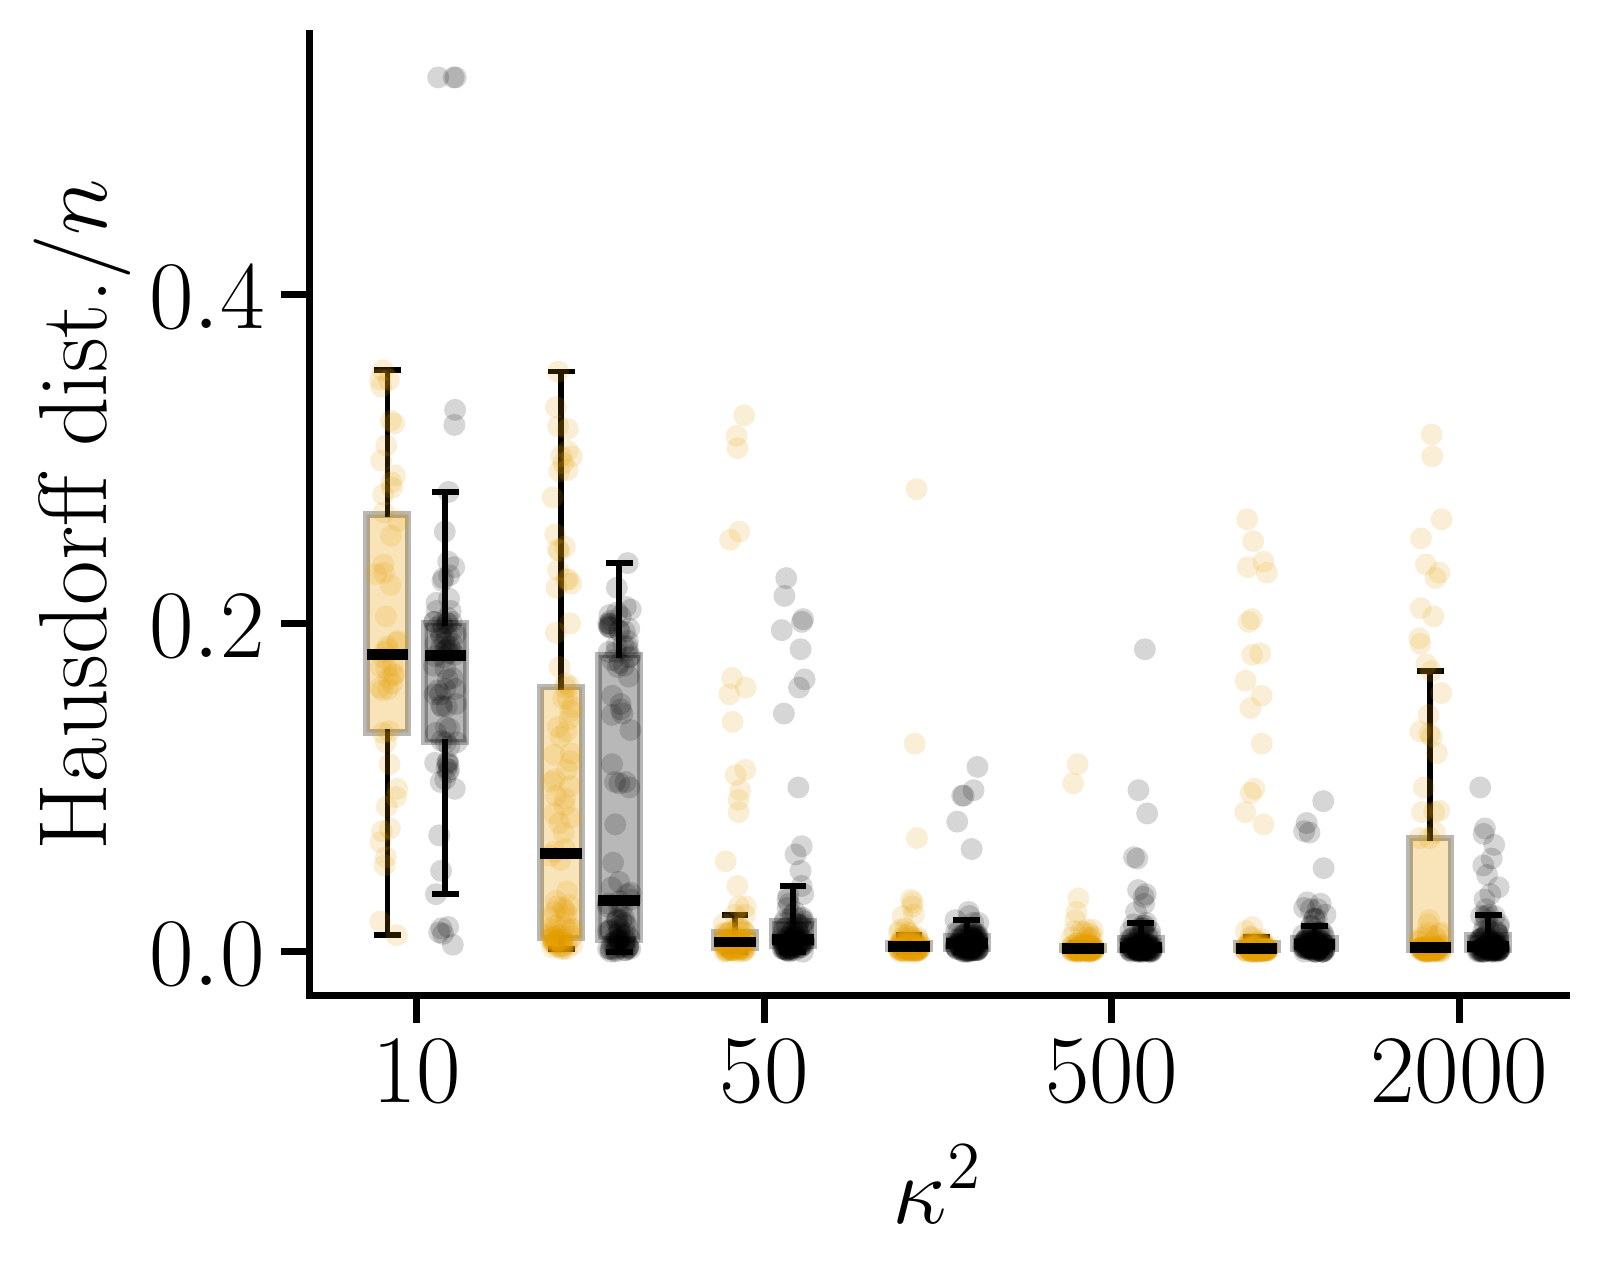

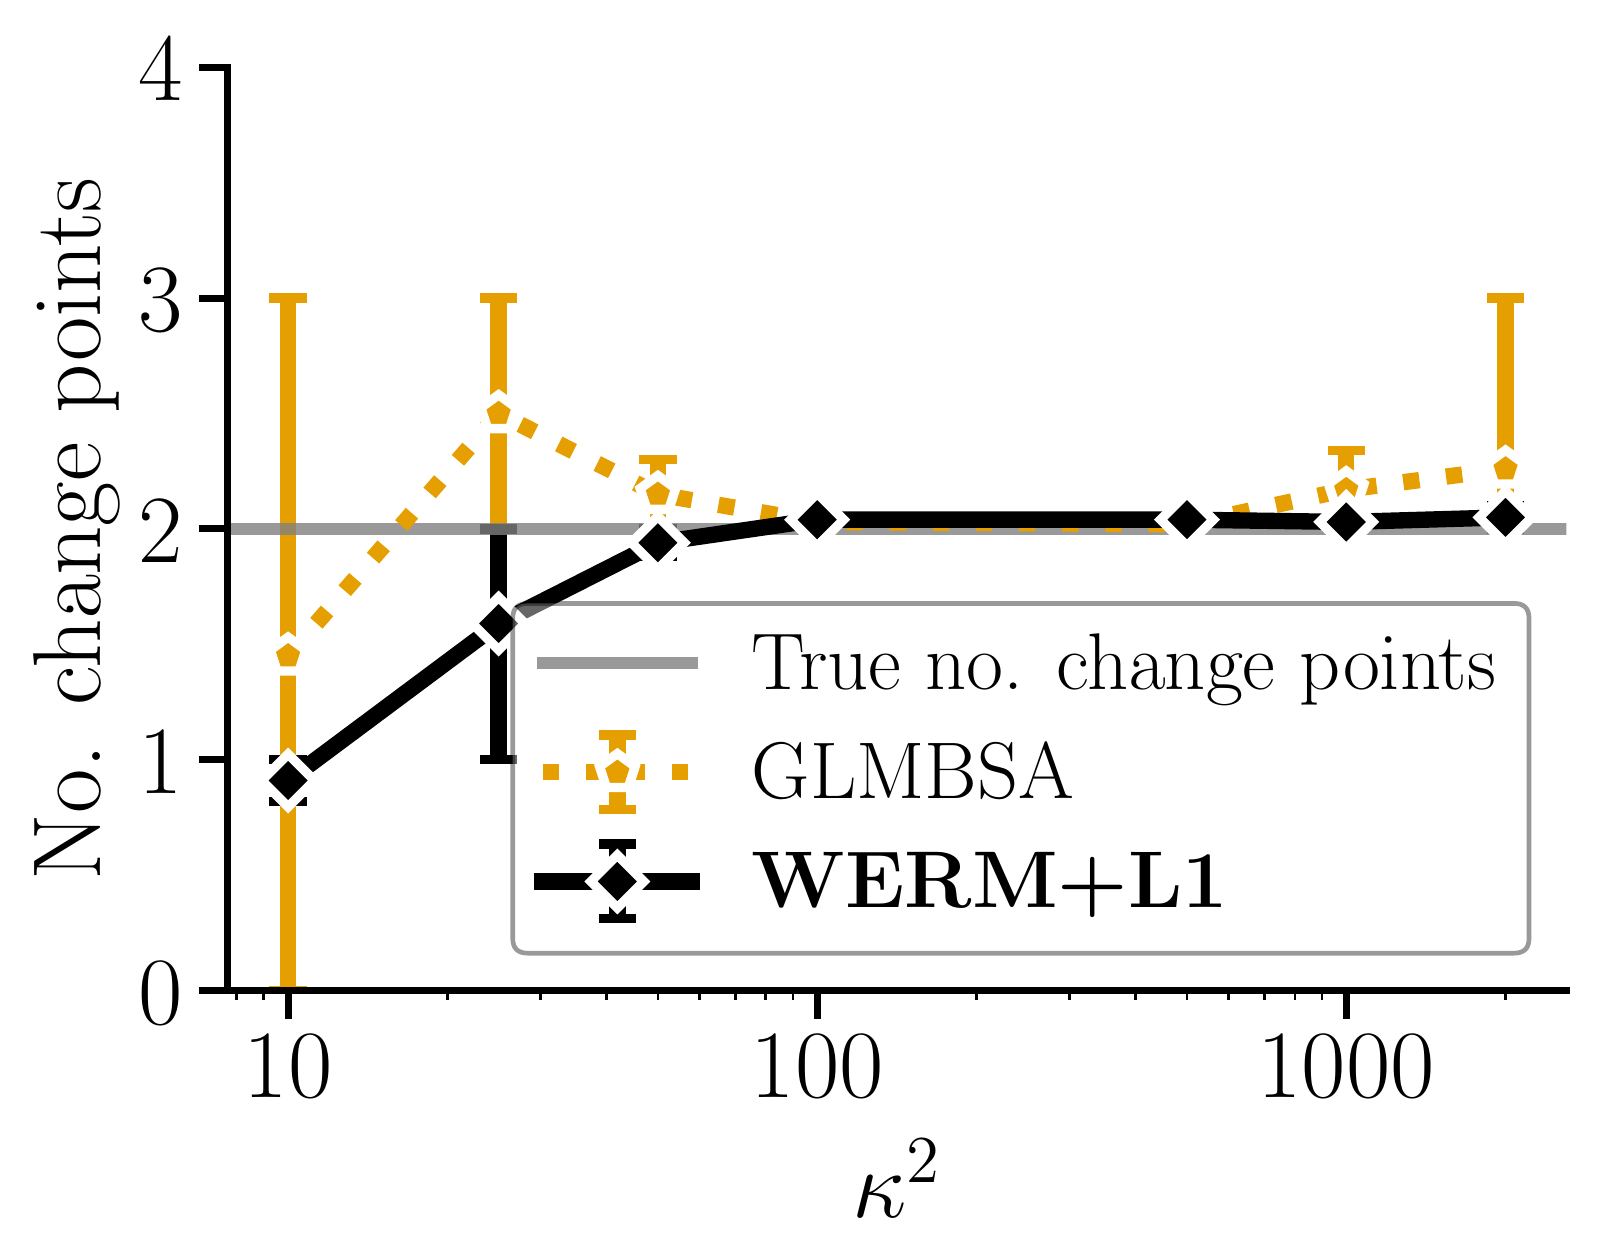

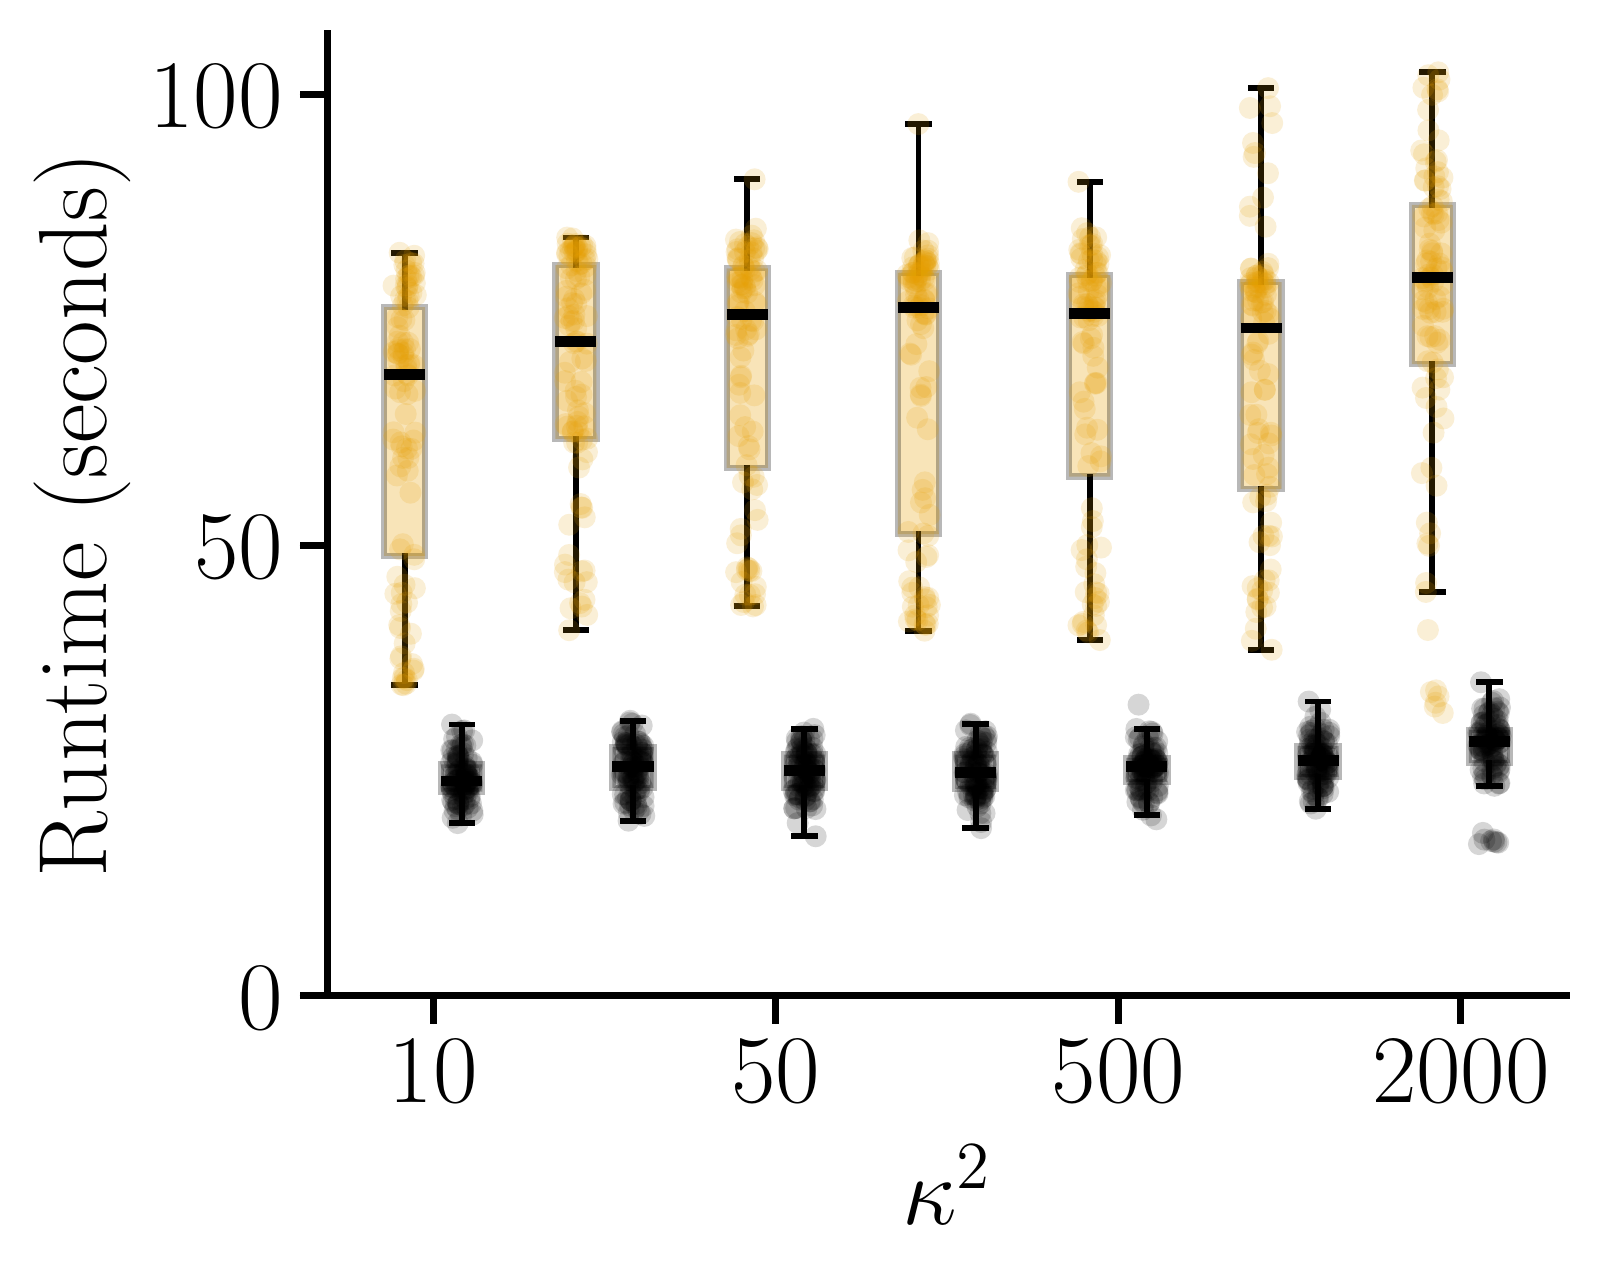

In [4]:
panels = ['results/M3_usample_final_plots/final_M3_upsample_format_M3_usample_final_delta6_alpha01_GLMBSA_WERM-L1_fullCV2_seed42_100trials_two_method_2fold_location_boxplots.pdf', 'results/M3_usample_final_plots/final_M3_upsample_format_M3_usample_final_delta6_alpha01_GLMBSA_WERM-L1_fullCV2_seed42_100trials_two_method_2fold_size_asymmetric_errors.pdf', 'results/M3_usample_final_plots/final_M3_upsample_format_M3_usample_final_delta6_alpha01_GLMBSA_WERM-L1_fullCV2_seed42_100trials_two_method_2fold_runtime_boxplots.pdf'] if REGENERATE_FIGURES else ['figures/figure_09/panel_01.pdf', 'figures/figure_09/panel_02.pdf', 'figures/figure_09/panel_03.pdf']
show_panels(panels)
